# Exploring the UCI Student Performance dataset

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether the kernel starts in the repository root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATASET = "mat"  # "mat" = maths course (395 students), "por" = Portuguese course (649 students)
PASS_THRESHOLD = 10  # pass = final grade G3 >= 10 (scale 0-20)

# Same as running `uv run python scripts/download_data.py` from the repository root.
# It does nothing if the files are already present and their checksums match.
subprocess.run([sys.executable, str(ROOT / "scripts" / "download_data.py")], check=True)

DATA_DIR = ROOT / "data" / "raw" / "student-performance"
df = pd.read_csv(DATA_DIR / f"student-{DATASET}.csv", sep=";")
print(f"Loaded student-{DATASET}.csv: {df.shape[0]} students, {df.shape[1]} columns")

Dataset already present and verified: /storage3/DSIP/rriva/teaching/data_use_ce/data/raw/student-performance
Loaded student-mat.csv: 395 students, 33 columns


## Where the data comes from

- **Dataset page:** [UCI Machine Learning Repository, *Student Performance*](https://archive.ics.uci.edu/dataset/320/student+performance), DOI [10.24432/C5TG7T](https://doi.org/10.24432/C5TG7T).
- **Original paper:** P. Cortez and A. M. G. Silva (2008), *Using data mining to predict secondary school student performance*, Proc. 5th Annual Future Business Technology Conference (FUBUTEC).
- **Licence:** CC BY 4.0, as stated in the project brief. The UCI API entry has no licence field, so this still needs checking on the dataset page.
- **Two files:** `student-mat.csv` (maths) and `student-por.csv` (Portuguese). Both describe secondary-school students from two Portuguese schools, GP and MS. The official documentation says that 382 students appear in both files.
- **Separator:** semicolons (`;`), not commas.

The documentation shipped inside the archive is printed below. It lists every column and its meaning.

In [2]:
print((DATA_DIR / "student.txt").read_text(encoding="utf-8"))

# Attributes for both student-mat.csv (Math course) and student-por.csv (Portuguese language course) datasets:
1 school - student's school (binary: "GP" - Gabriel Pereira or "MS" - Mousinho da Silveira)
2 sex - student's sex (binary: "F" - female or "M" - male)
3 age - student's age (numeric: from 15 to 22)
4 address - student's home address type (binary: "U" - urban or "R" - rural)
5 famsize - family size (binary: "LE3" - less or equal to 3 or "GT3" - greater than 3)
6 Pstatus - parent's cohabitation status (binary: "T" - living together or "A" - apart)
7 Medu - mother's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
8 Fedu - father's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
9 Mjob - mother's job (nominal: "teacher", "health" care related, civil "services" (e.g. administrative or police), "at_home" or 

## Shape, types and missing values

Column names are the original UCI ones. Their meanings are in the documentation above.

In [3]:
display(df.head())
print("Missing values in total:", int(df.isna().sum().sum()))
df.describe().T

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Missing values in total: 0


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


## The target: final grade `G3` and "pass"

`G3` is the final grade, from 0 to 20. The brief defines *pass* as `G3 >= 10`.

Some students have `G3 == 0`. The brief suggests they did not sit the final exam. The next cells look at that.

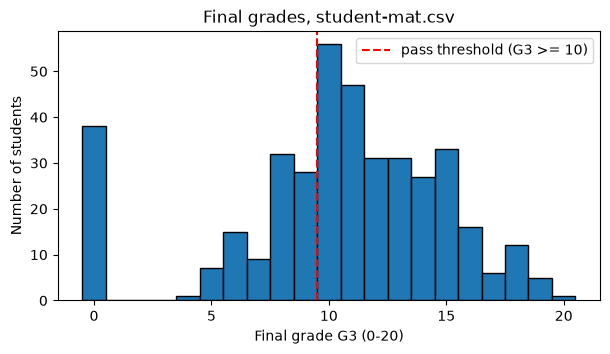

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df["G3"], bins=np.arange(-0.5, 21.5, 1), edgecolor="black")
ax.axvline(PASS_THRESHOLD - 0.5, color="red", linestyle="--", label="pass threshold (G3 >= 10)")
ax.set_xlabel("Final grade G3 (0-20)")
ax.set_ylabel("Number of students")
ax.set_title(f"Final grades, student-{DATASET}.csv")
ax.legend()
plt.show()

In [5]:
df["pass"] = (df["G3"] >= PASS_THRESHOLD).astype(int)
n_zero = int((df["G3"] == 0).sum())
print(f"Pass rate, all students:      {df['pass'].mean():.1%}")
print(f"Students with G3 == 0:        {n_zero} ({n_zero / len(df):.1%})")
print(f"Pass rate, excluding G3 == 0: {df.loc[df['G3'] > 0, 'pass'].mean():.1%}")

Pass rate, all students:      67.1%
Students with G3 == 0:        38 (9.6%)
Pass rate, excluding G3 == 0: 74.2%


In [6]:
f"{(df['G3'] >= PASS_THRESHOLD).astype(int).mean():.2%}"

'67.09%'

### Do the `G3 == 0` students look different?

If they missed the final exam, they should still have grades from the earlier periods (`G1`, `G2`) and some absences.

In [7]:
df.assign(zero_final=df["G3"] == 0).groupby("zero_final")[["G1", "G2", "absences"]].describe().T

zero_final           False      True 
G1       count  357.000000  38.000000
         mean    11.268908   7.526316
         std      3.240450   1.811925
         min      3.000000   4.000000
         25%      9.000000   6.000000
         50%     11.000000   7.000000
         75%     14.000000   9.000000
         max     19.000000  12.000000
G2       count  357.000000  38.000000
         mean    11.358543   4.657895
         std      3.147188   3.700083
         min      5.000000   0.000000
         25%      9.000000   0.000000
         50%     11.000000   5.000000
         75%     14.000000   8.000000
         max     19.000000  10.000000
absences count  357.000000  38.000000
         mean     6.316527   0.000000
         std      8.187623   0.000000
         min      0.000000   0.000000
         25%      2.000000   0.000000
         50%      4.000000   0.000000
         75%      8.000000   0.000000
         max     75.000000   0.000000

## Pass rate by group

The bars include the `G3 == 0` students. How to handle them is still an open decision.

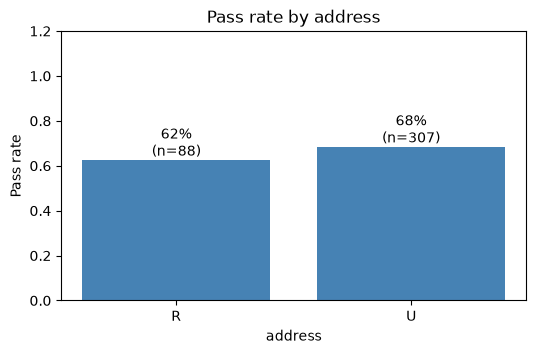

,n,pass_rate
address,,
R,88,0.625000
U,307,0.684039


In [8]:
def pass_rate_by(column: str, data: pd.DataFrame = df) -> pd.DataFrame:
    """Bar chart of the pass rate for each category of `column`, with group sizes."""
    table = data.groupby(column)["pass"].agg(n="size", pass_rate="mean")
    fig, ax = plt.subplots(figsize=(6, 3.5))
    labels = table.index.astype(str)
    ax.bar(labels, table["pass_rate"], color="steelblue")
    for i, (rate, n) in enumerate(zip(table["pass_rate"], table["n"], strict=True)):
        ax.text(i, rate + 0.02, f"{rate:.0%}\n(n={n})", ha="center")
    ax.set_ylim(0, 1.2)
    ax.set_ylabel("Pass rate")
    ax.set_xlabel(column)
    ax.set_title(f"Pass rate by {column}")
    plt.show()
    return table


pass_rate_by("address")

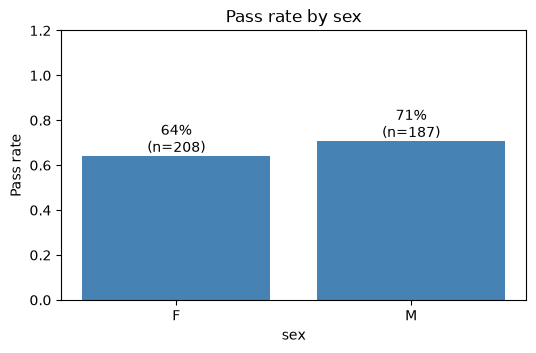

,n,pass_rate
sex,,
F,208,0.639423
M,187,0.705882


In [9]:
pass_rate_by("sex")

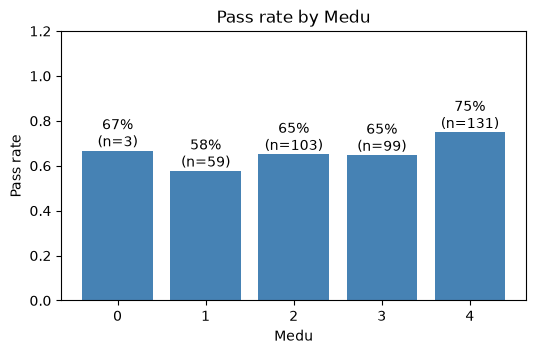

,n,pass_rate
Medu,,
0,3,0.666667
1,59,0.576271
2,103,0.650485
3,99,0.646465
4,131,0.748092


In [10]:
pass_rate_by("Medu")

## Study time, absences and grades

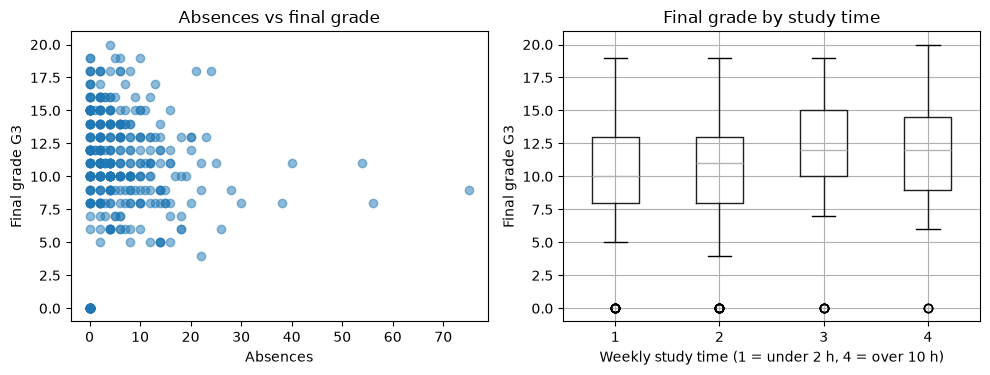

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(df["absences"], df["G3"], alpha=0.5)
axes[0].set_xlabel("Absences")
axes[0].set_ylabel("Final grade G3")
axes[0].set_title("Absences vs final grade")

df.boxplot(column="G3", by="studytime", ax=axes[1])
axes[1].set_xlabel("Weekly study time (1 = under 2 h, 4 = over 10 h)")
axes[1].set_ylabel("Final grade G3")
axes[1].set_title("Final grade by study time")
plt.suptitle("")
plt.tight_layout()
plt.show()

## Which variables go together?

Cross-tables for address against travel time and internet access. These are the kinds of relationships a model can use as indirect ("proxy") information about a student's background.

In [12]:
display(pd.crosstab(df["address"], df["traveltime"], margins=True))
display(pd.crosstab(df["address"], df["internet"], margins=True))

traveltime,1,2,3,4,All
address,,,,,
R,35,34,14,5,88
U,222,73,9,3,307
All,257,107,23,8,395


internet,no,yes,All
address,,,
R,28,60,88
U,38,269,307
All,66,329,395


## Exploration

In [13]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'pass'],
      dtype='str')

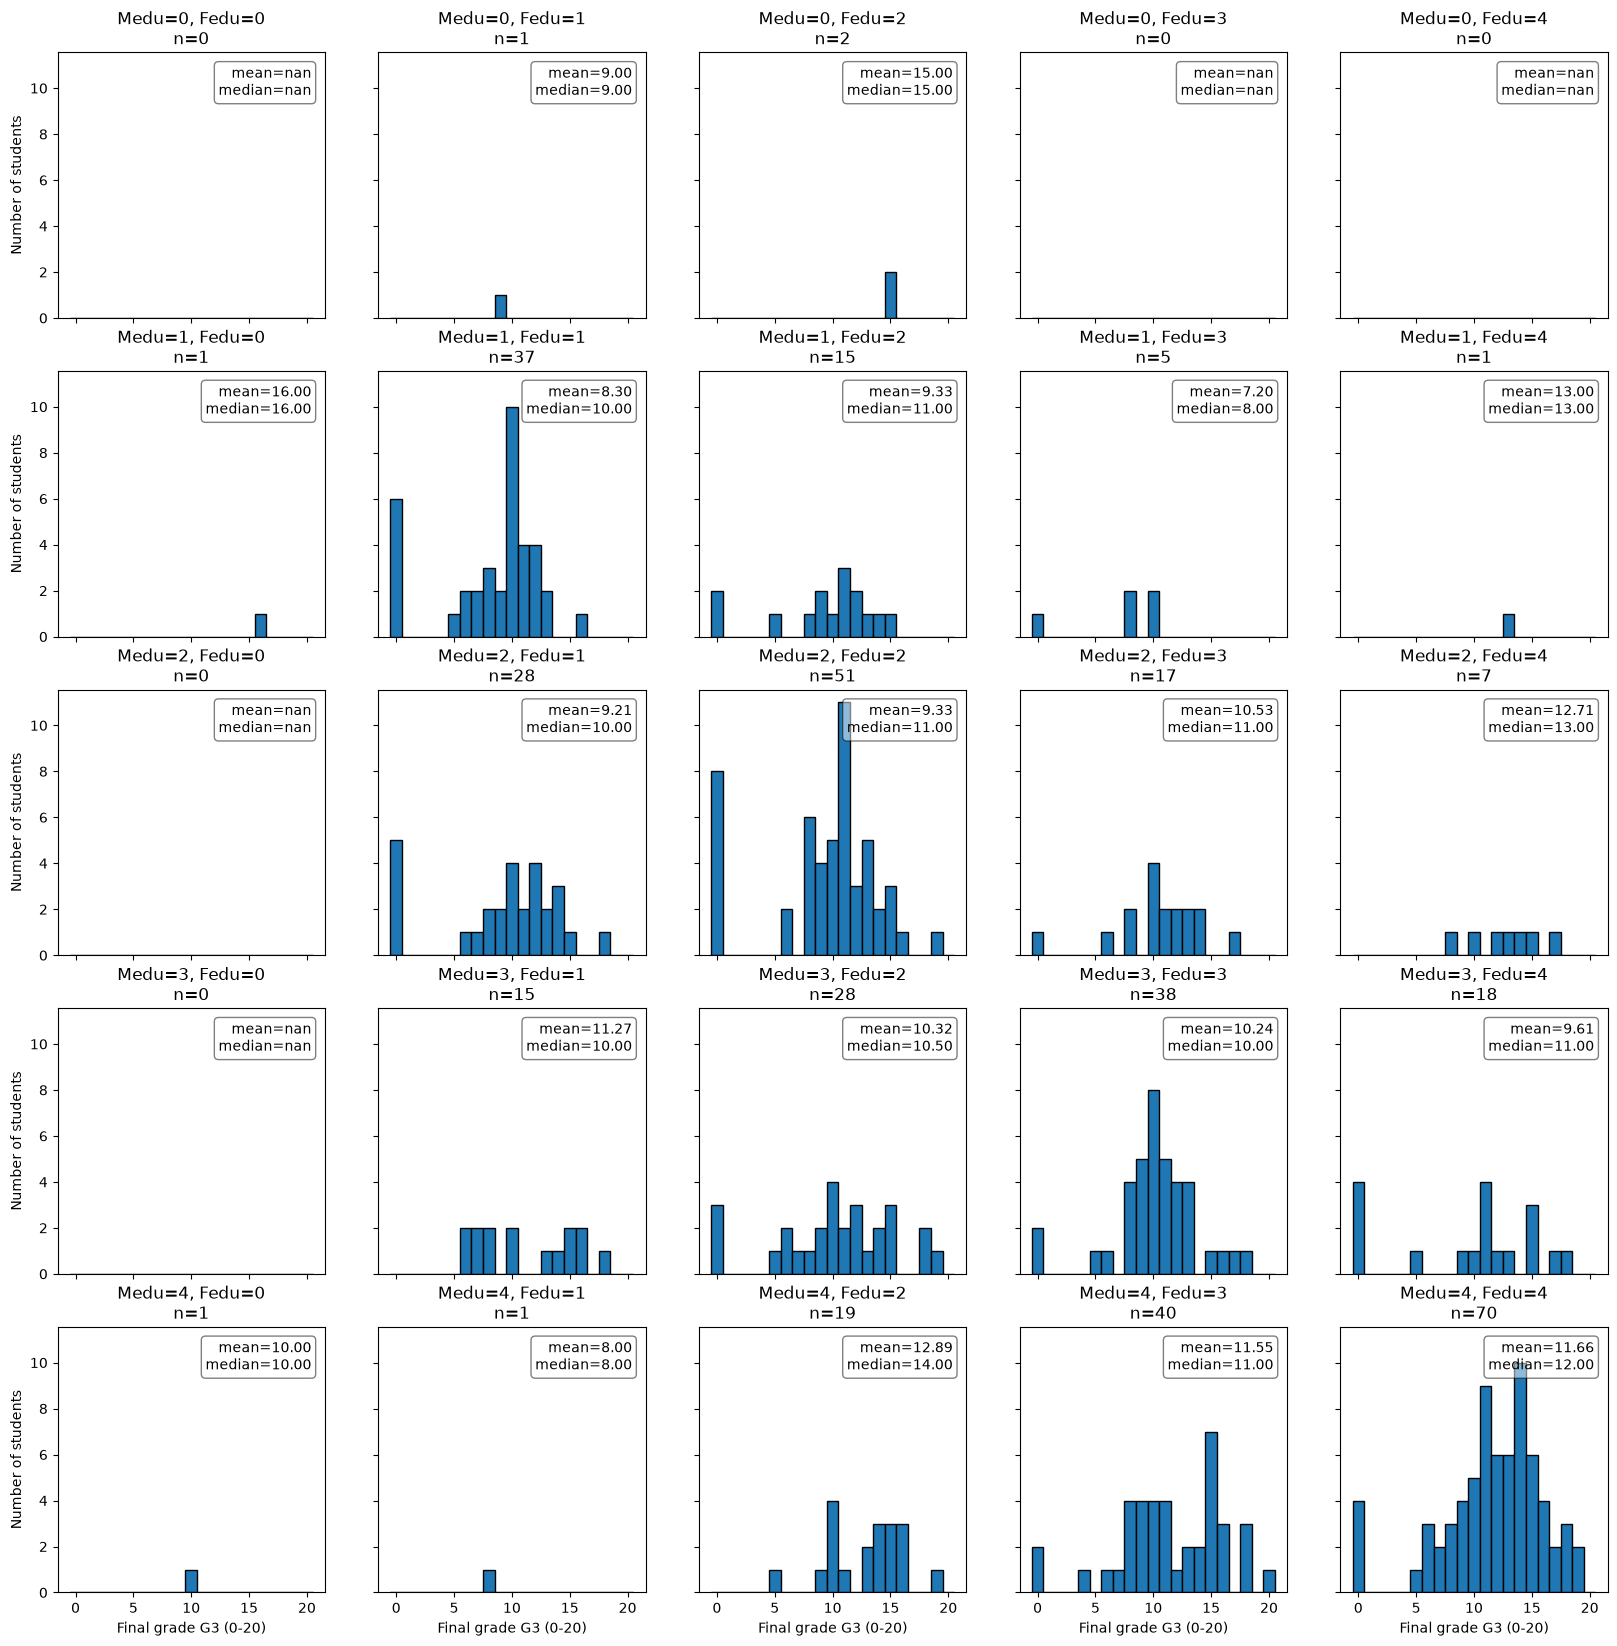

In [14]:
# grid of histograms, showing the distribution of G3 (final grade) for every combination of Medu and
# Fedu

plot_cols = ["Medu", "Fedu"]
n_rows = df[plot_cols[0]].nunique()
n_cols = df[plot_cols[1]].nunique()

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 4), sharex=True, sharey=True)
for i, medu in enumerate(sorted(df["Medu"].unique())):
    for j, fedu in enumerate(sorted(df["Fedu"].unique())):
        ax = axes[i, j]
        subset = df[(df["Medu"] == medu) & (df["Fedu"] == fedu)]
        ax.hist(subset["G3"], bins=np.arange(-0.5, 21.5, 1), edgecolor="black")
        ax.set_title(f"Medu={medu}, Fedu={fedu}\nn={len(subset)}")
        # claculate mean and median of G3 for the subset and display the values in a legend-like box
        # in the top right corner of the histogram
        mean_g3 = subset["G3"].mean()
        median_g3 = subset["G3"].median()
        ax.text(
            0.95,
            0.95,
            f"mean={mean_g3:.2f}\nmedian={median_g3:.2f}",
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment="top",
            horizontalalignment="right",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.5),
        )

        if i == n_rows - 1:
            ax.set_xlabel("Final grade G3 (0-20)")
        if j == 0:
            ax.set_ylabel("Number of students")

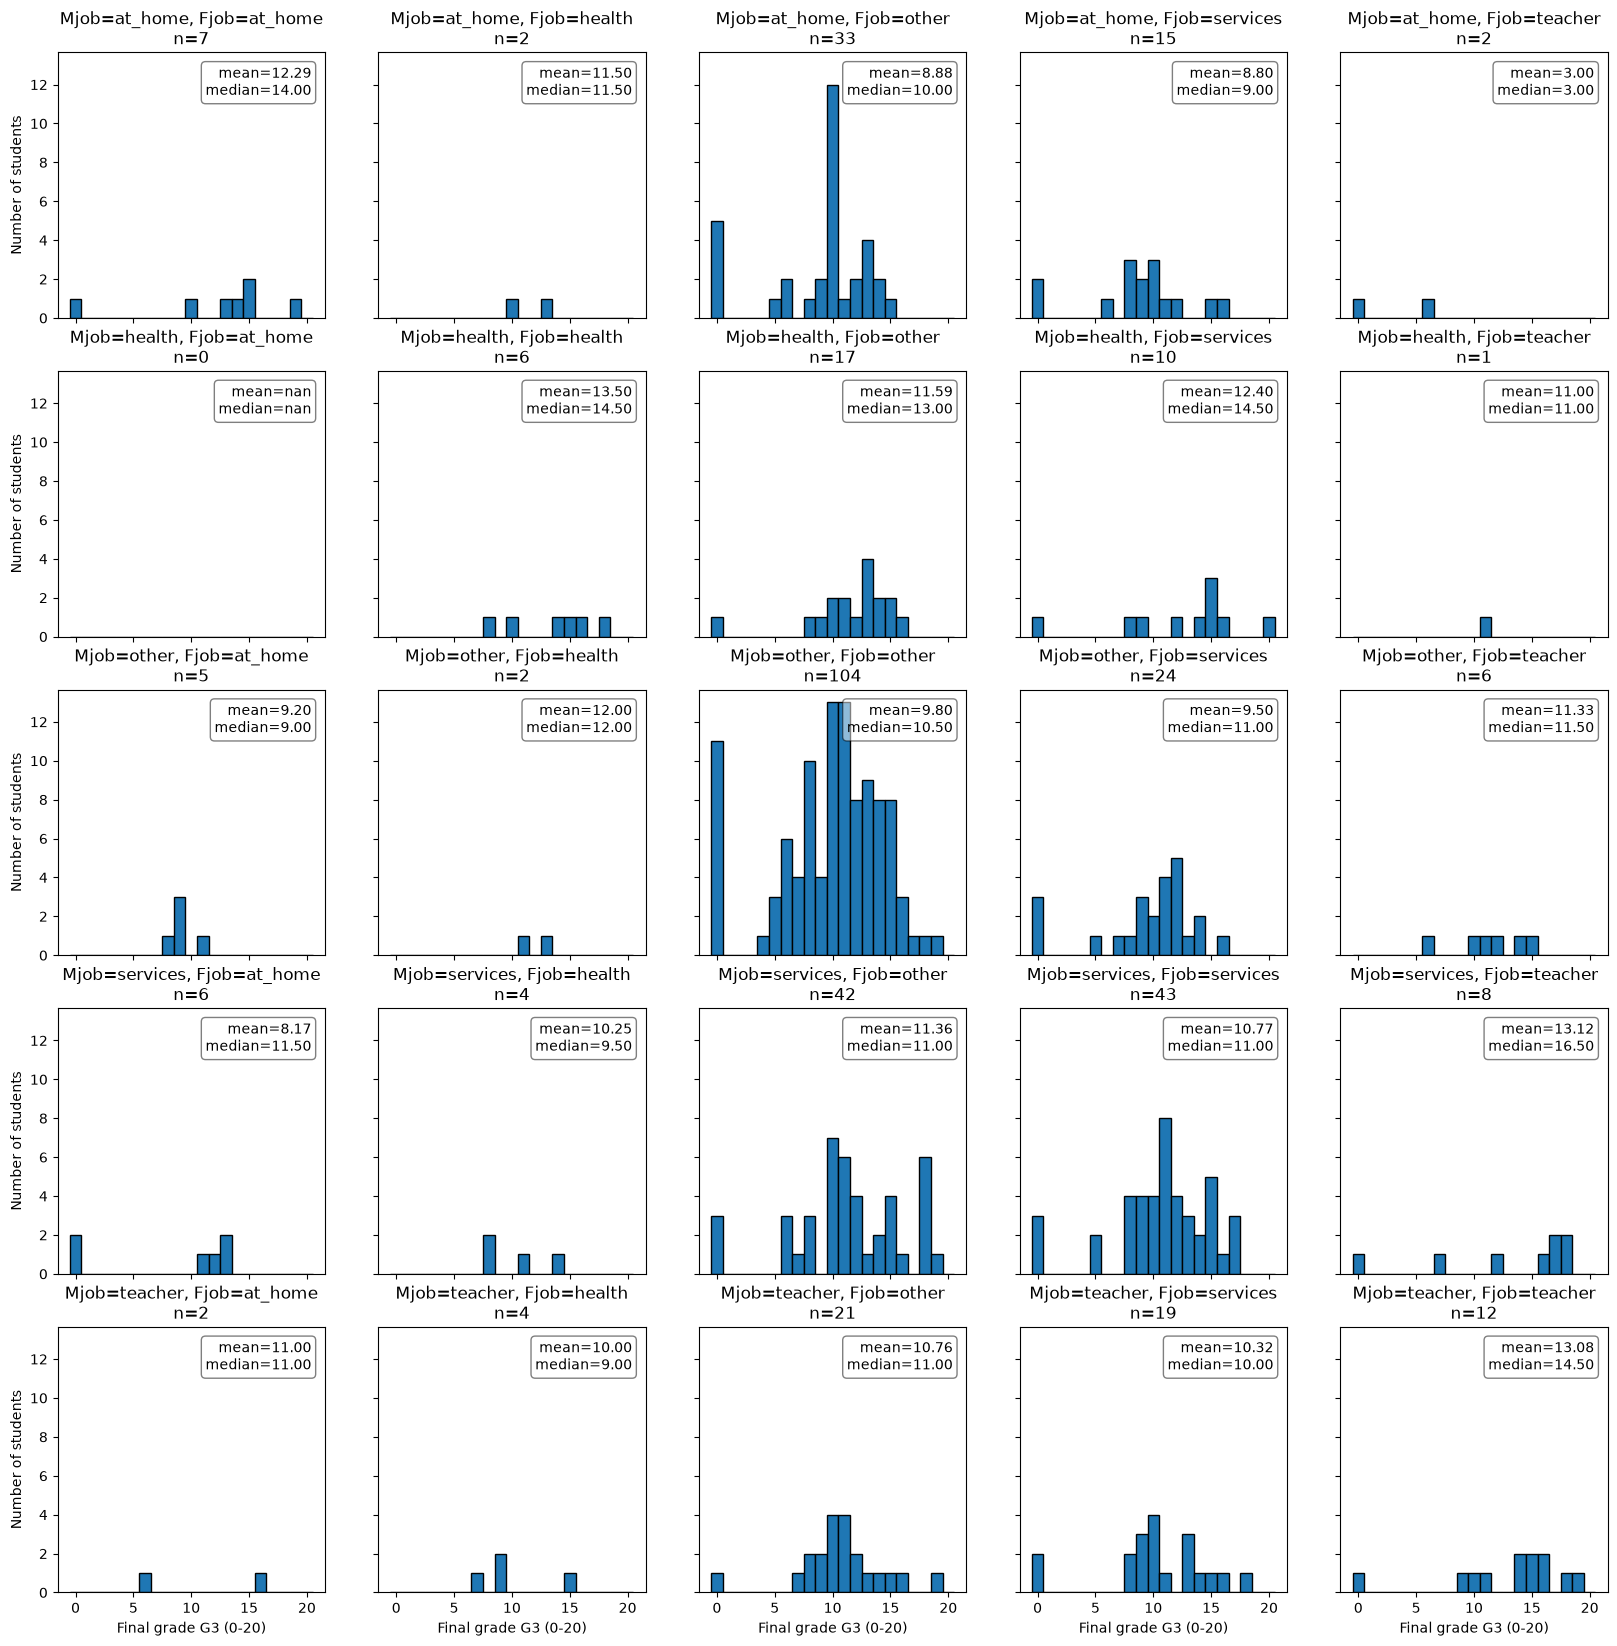

In [15]:
# grid of histograms, showing the distribution of G3 (final grade) for every combination of Mjob and
# Fjob

plot_cols = ["Mjob", "Fjob"]
n_rows = df[plot_cols[0]].nunique()
n_cols = df[plot_cols[1]].nunique()

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 4), sharex=True, sharey=True)
for i, mjob in enumerate(sorted(df["Mjob"].unique())):
    for j, fjob in enumerate(sorted(df["Fjob"].unique())):
        ax = axes[i, j]
        subset = df[(df["Mjob"] == mjob) & (df["Fjob"] == fjob)]
        ax.hist(subset["G3"], bins=np.arange(-0.5, 21.5, 1), edgecolor="black")
        ax.set_title(f"Mjob={mjob}, Fjob={fjob}\nn={len(subset)}")
        # claculate mean and median of G3 for the subset and display the values in a legend-like box
        # in the top right corner of the histogram
        mean_g3 = subset["G3"].mean()
        median_g3 = subset["G3"].median()
        ax.text(
            0.95,
            0.95,
            f"mean={mean_g3:.2f}\nmedian={median_g3:.2f}",
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment="top",
            horizontalalignment="right",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.5),
        )

        if i == n_rows - 1:
            ax.set_xlabel("Final grade G3 (0-20)")
        if j == 0:
            ax.set_ylabel("Number of students")

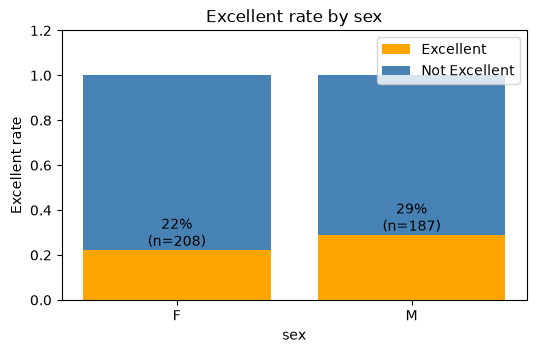

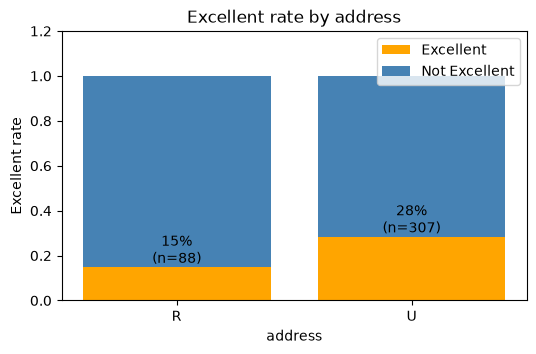

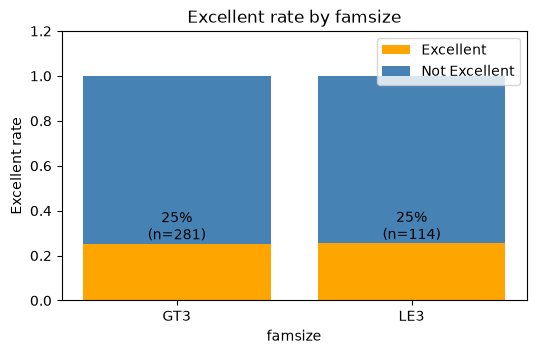

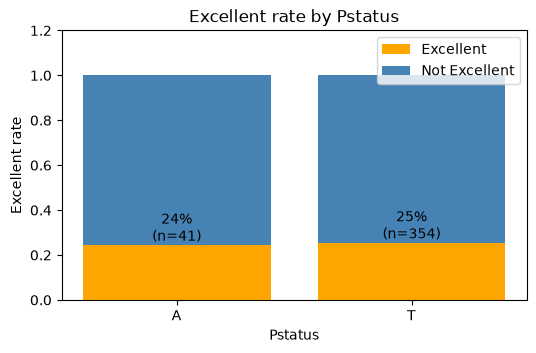

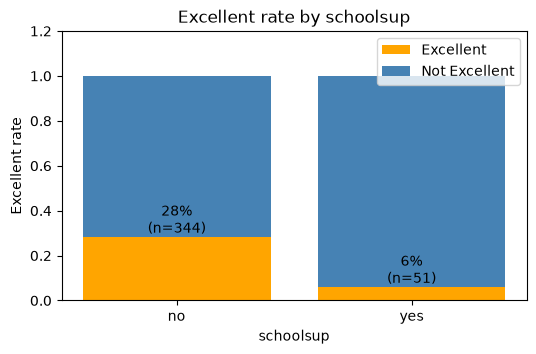

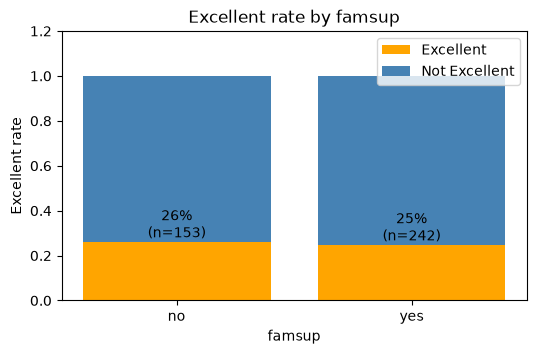

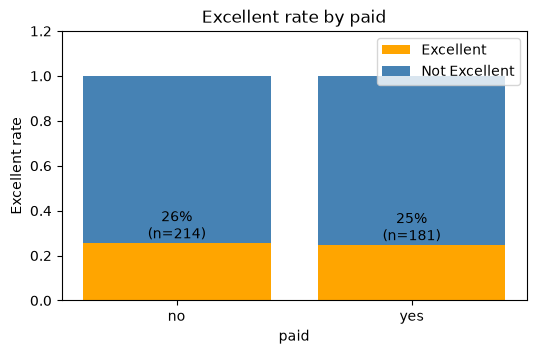

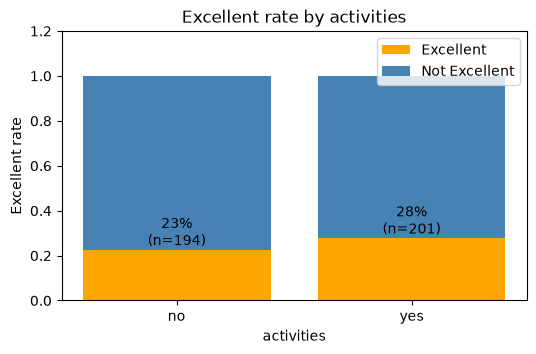

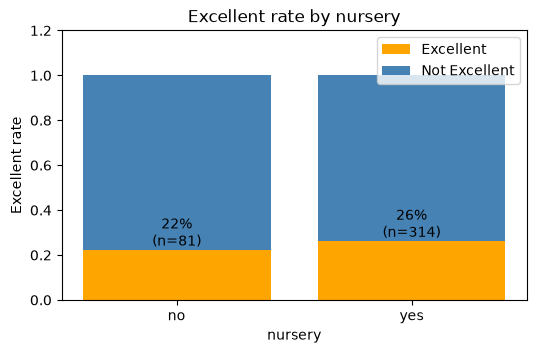

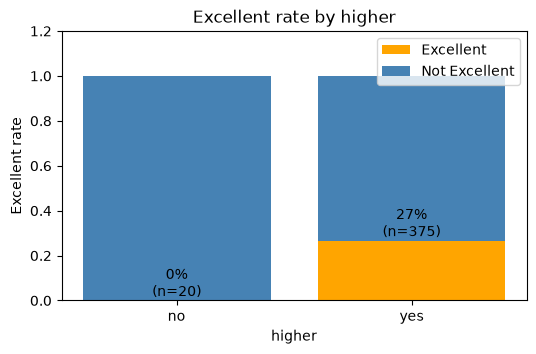

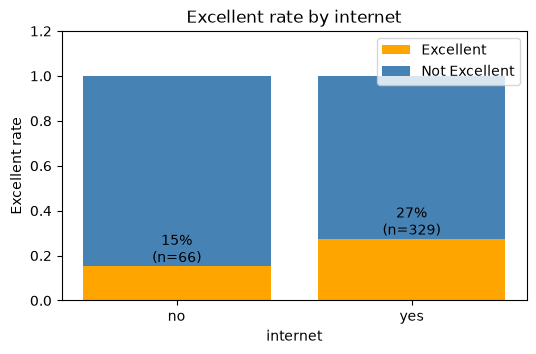

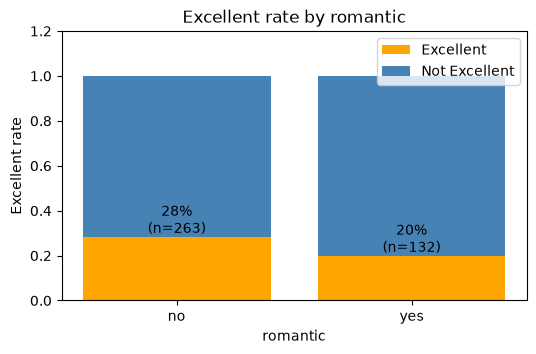

In [16]:
# set a EXCELLENCE_TRESHOLD for G3, at or above which we consider the student to have performed
# excellently. Then plot different feature histograms/bars for excellent and non excellent students
# orange and blue bars are plotted one next to the other
# plot the ratio over the total value
EXCELLENCE_THRESHOLD = 14
df["Excellent"] = df["G3"] >= EXCELLENCE_THRESHOLD

for col in [
    "sex",
    "address",
    "famsize",
    "Pstatus",
    "schoolsup",
    "famsup",
    "paid",
    "activities",
    "nursery",
    "higher",
    "internet",
    "romantic",
]:
    table = df.groupby(col)["Excellent"].agg(n="size", excellent_rate="mean")
    fig, ax = plt.subplots(figsize=(6, 3.5))
    labels = table.index.astype(str)
    ax.bar(labels, table["excellent_rate"], color="orange", label="Excellent")
    ax.bar(
        labels,
        1 - table["excellent_rate"],
        bottom=table["excellent_rate"],
        color="steelblue",
        label="Not Excellent",
    )

    for i, (rate, n) in enumerate(zip(table["excellent_rate"], table["n"], strict=True)):
        ax.text(i, rate + 0.02, f"{rate:.0%}\n(n={n})", ha="center")
        # on the x-axis, display also the number of students in each category, e.g.
        # "M=male\n(n=200)"
        # ax.text(i, -0.1, f"(n={n})", ha="center", transform=ax.transAxes)

    ax.set_ylim(0, 1.2)
    ax.set_ylabel("Excellent rate")
    ax.set_xlabel(col)
    ax.set_title(f"Excellent rate by {col}")
    ax.legend()
    plt.show()